Mounted at /content/drive


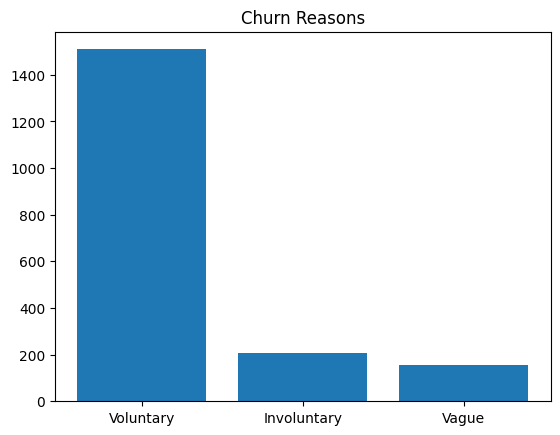

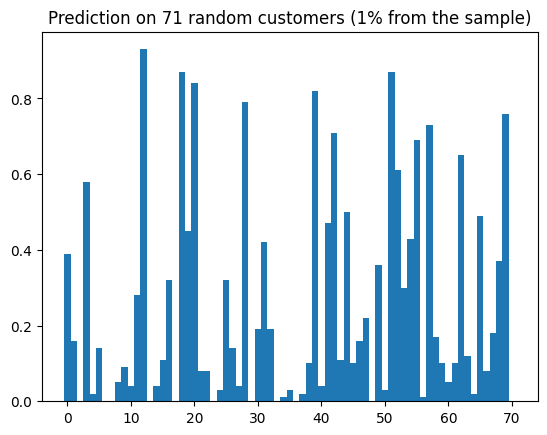

71


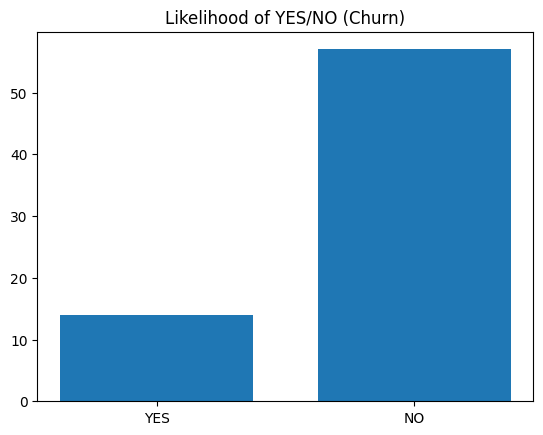

14
57
0.22 NO


In [ ]:
import sys
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from numpy import extract
import pandas as pd
from google.colab import drive

drive.mount('/content/drive',force_remount=True)
Customers=pd.read_excel('/content/drive/MyDrive/AISC_Project/Telco_customer_churn.xlsx')

class Customer:
  def __init__(self,id,tenure_months,contract_type,payment_method,monthly_fee,total_charges,churn_risk_score,ltv):
    self.id=id
    self.tenure_months=tenure_months
    self.contract_type=contract_type
    self.payment_method=payment_method
    self.monthly_fee=monthly_fee
    self.total_charges=total_charges
  def InMachine(self)->None:
    pass

class Notebook:
  Voluntary=[
      "Competitor made better offer",
      "Competitor had better devices",
      "Competitor offered higher download speeds",
      "Competitor offered more data",
      "Product dissatisfaction",
      "Service dissatisfaction",
      "Long distance charges",
      "Attitude of service provider",
      "Attitude of support person",
      "Poor expertise of online support",
      "Poor expertise of phone support",
      "Extra data charges",
      "Price too high",
      "Lack of affordable download/upload speed",
      "Lack of self-service on Website"
  ]

  Involuntary=[
      "Limited range of services",
      "Network reliability",
      "Deceased",
      "Moved"
  ]

  Vague=[
      "Don't know"
  ]

  def __init__(self,info:Customer):
      self.info=info
  def print(self):
    return Customers

  def Clean(self):
    extracted=Customers.loc[Customers["Total Charges"]==" "]
    f=Customers.drop(extracted.index)
    return f

  def findUnique(self,label:str):
    f=Customers[label].unique()
    for items in f:
      print(items)

  def makeComparision(self)->None:
    pass

  def getProperty(self,prop):
    extracted=Customers.loc[Customers["Churn Reason"].isin(prop)]
    return extracted

  def RateService(self):

    plt.title("Churn Reasons")
    x = np.array(["Voluntary", "Involuntary","Vague"])
    y = np.array([len(self.getProperty(self.Voluntary)), len(self.getProperty(self.Involuntary)),len(self.getProperty(self.Vague))])

    plt.bar(x,y)
    plt.show()

TestList=Notebook((123,3,"permanent","cash",1000,10000,24.0,124.3))
TestList.RateService()

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

FilteredData=TestList.Clean()

# Shuffle the sample
FilteredData=FilteredData.sample(frac=1).reset_index(drop=True)
y=FilteredData["Churn Value"]

ChosenFeatures=["Tenure Months","Monthly Charges","Total Charges","CLTV"]
X=FilteredData[ChosenFeatures]

train_X, val_X, train_y, val_y = train_test_split(X, y, test_size=0.01,random_state=42)

_model=RandomForestRegressor(random_state=42)
_model.fit(train_X,train_y)

preds = _model.predict(val_X)

plt.title("Prediction on 71 random customers (1% from the sample)")
x = np.array(list(range(len(preds))))
y = np.array(preds)
plt.bar(x,y,width=1)
plt.show()

print(len(preds))

plt.title("Likelihood of YES/NO (Churn)")
GetLikelyYes=extract(preds>=0.5,preds)
GetLikelyNo=extract(preds<0.5,preds)
x=np.array(["YES","NO"])
y=np.array([len(GetLikelyYes),len(GetLikelyNo)])
plt.bar(x,y,width=0.75)
plt.show()

print(len(GetLikelyYes))
print(len(GetLikelyNo))

# *Assumption: in 71 customers, Random Forest Regression predicts there will be <30% customers who leave the product.

# Another insight is that : The Involuntary Churn is something could not contribute to the enterprise's Action Plan
# (Unchangeable, unless the enterprise intentionally resolves the problem - restructure / ... sth like that)
# We could say the Voluntary Churn plays a main role in enclosuring the Customer Churn for a new Action Plan

Tenure_Month=[4]
Monthly_Fee=[10]
Total_Charges=[40]
CLTV=[56]


MakeList=pd.DataFrame({"Tenure Months":Tenure_Month,"Monthly Charges":Monthly_Fee,"Total Charges":Total_Charges,"CLTV":CLTV})
NewPred=_model.predict(MakeList)

for items in NewPred:
  print(items,end=" ")
  if items>=0.5:
    print("YES")
  else:
    print("NO")


Mounted at /content/drive

--- RANDOM TEST ---

Refreshing Times: 8

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
5,3848,1,1,2,33.982193,33.982193,1,3600,3,0.84
2,5755,14,3,3,45.183752,632.572527,0,2721,0,0.16
19,2599,16,3,2,105.900921,1694.414740,1,3262,2,0.51
7,1473,23,3,3,71.633956,1647.580978,0,2229,0,0.00
10,7641,24,3,4,67.497072,1619.929723,0,3077,0,0.17
4,2468,26,2,3,74.213944,1929.562555,0,3856,0,0.00
9,6749,27,2,2,51.111049,1379.998333,0,3656,0,0.00
12,349,35,2,2,92.304969,3230.673916,0,3232,0,0.03
1,6076,39,2,1,22.585158,880.821171,0,2005,0,0.00
14,989,39,2,4,61.077780,2382.033412,0,3687,0,0.00



--> Yearly Gross:  52944.875208018704 



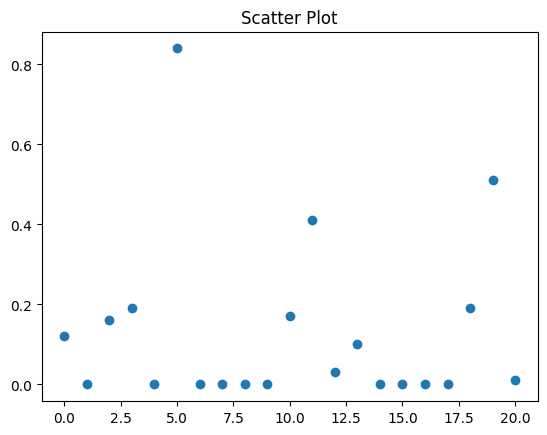

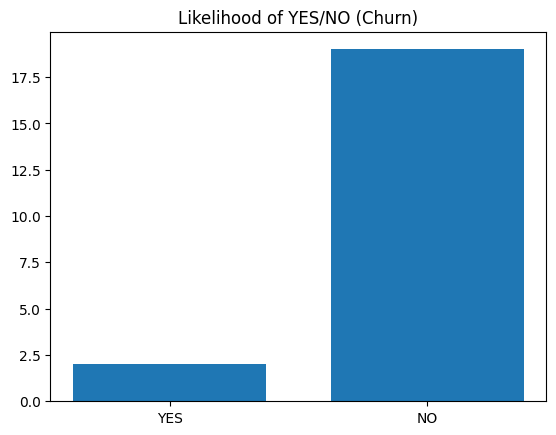

YES:  2
NO:  19

--- Service Evaluation ---


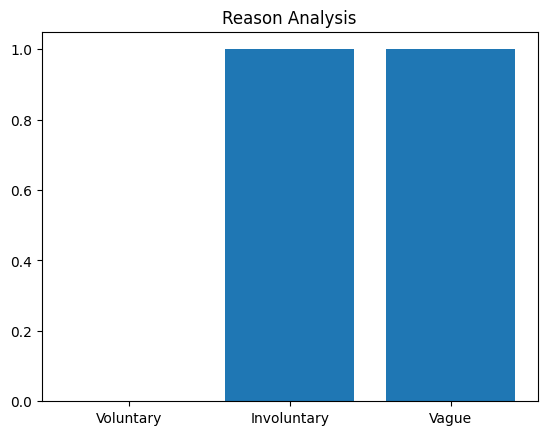

Voluntary:  0
Involuntary:  1
Vague:  1

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
2,2151,13,3,4,60.160498,782.086477,0,3321,0,0.14
1,5315,53,2,4,113.953367,6039.528463,0,2326,0,0.30
3,6471,58,2,3,105.920964,6143.415911,0,3310,0,0.26
0,967,71,2,4,83.904561,5957.223806,0,2797,0,0.13



--> Yearly Gross:  18922.254656838726 



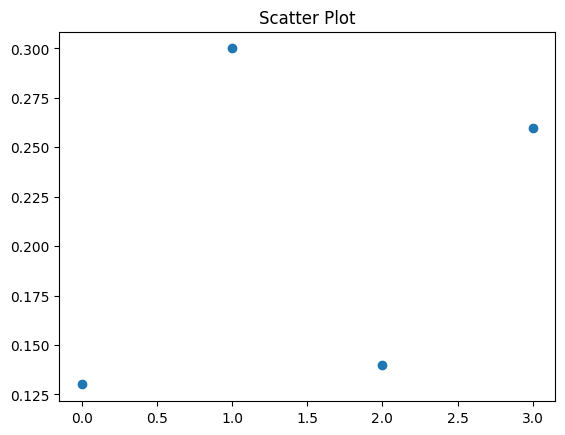

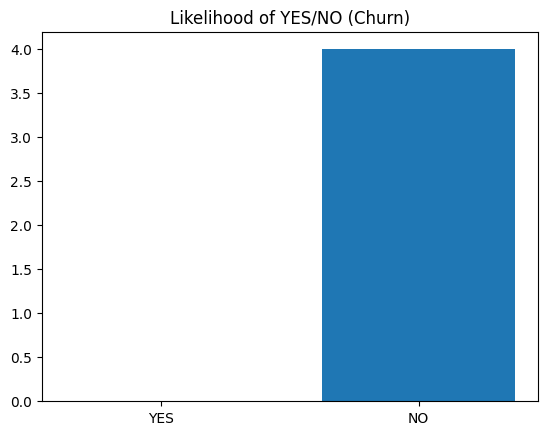

YES:  0
NO:  4

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
3,2366,0,1,4,72.547669,0.000000,1,2708,1,0.50
12,4753,0,1,2,27.588298,0.000000,0,3534,0,0.46
50,2386,0,1,4,48.406818,0.000000,1,2360,1,0.50
39,6882,1,1,4,53.286834,53.286834,1,2207,2,0.77
48,1319,2,1,4,37.517193,75.034386,1,2973,3,0.93
23,6886,3,1,2,38.251944,114.755831,0,3216,0,0.45
37,5032,3,1,4,61.499195,184.497585,0,3293,0,0.33
46,4169,6,1,4,37.073214,222.439283,0,3655,0,0.43
43,4154,6,1,4,46.749329,280.495973,0,3520,0,0.28
27,5026,6,1,1,101.512752,609.076513,1,2956,1,0.83



--> Yearly Gross:  134172.4361649684 



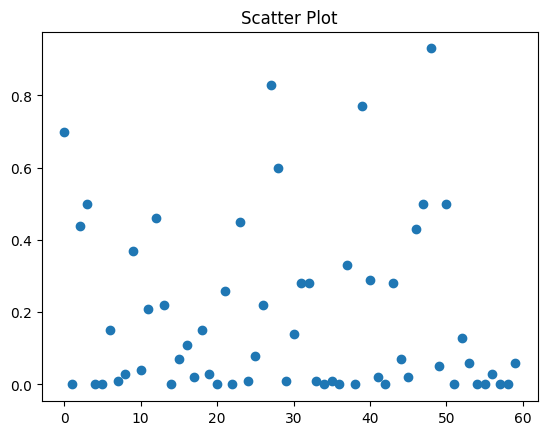

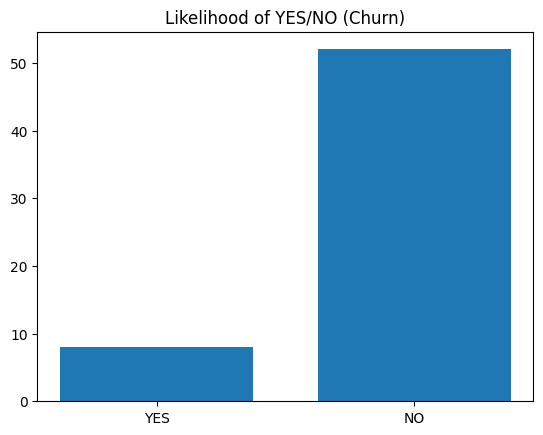

YES:  8
NO:  52

--- Service Evaluation ---


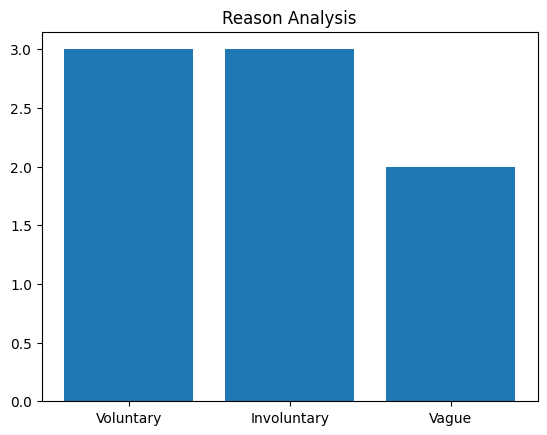

Voluntary:  3
Involuntary:  3
Vague:  2

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
35,391,0,1,1,27.949000,0.000000,1,3795,2,0.57
24,4255,1,1,1,57.366387,57.366387,1,3388,3,0.76
52,7901,1,1,3,71.533833,71.533833,1,2022,2,0.87
49,7165,2,1,1,116.345559,232.691117,0,3152,0,0.28
37,4217,3,1,4,89.131317,267.393952,1,2914,2,0.73
...,...,...,...,...,...,...,...,...,...,...
41,6498,67,2,1,70.202122,4703.542165,0,3908,0,0.06
20,4649,69,2,2,108.405870,7480.005044,0,3921,0,0.36
60,2133,70,2,4,101.468334,7102.783402,0,3103,0,0.03
17,581,71,2,3,21.764654,1545.290434,0,3479,0,0.00



--> Yearly Gross:  144419.3171895857 



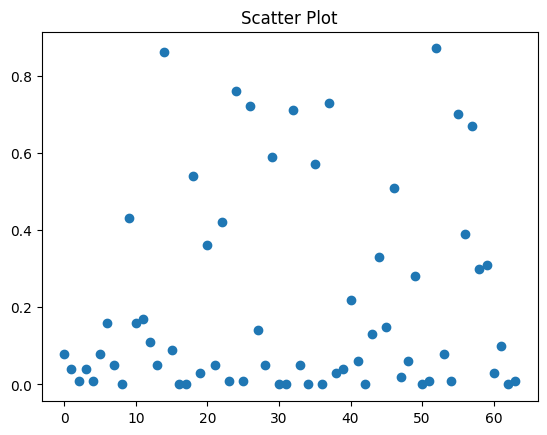

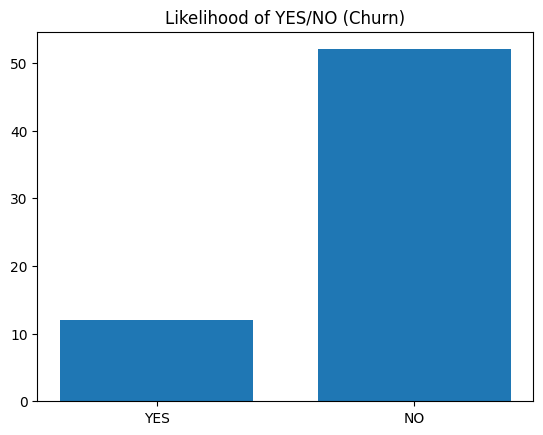

YES:  12
NO:  52

--- Service Evaluation ---


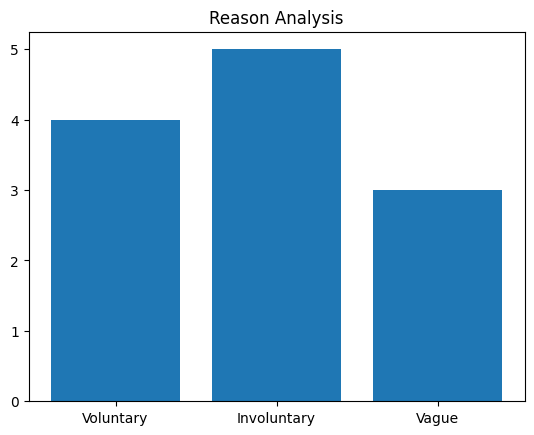

Voluntary:  4
Involuntary:  5
Vague:  3

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
10,6216,12,1,3,115.603630,1387.243566,1,3558,1,0.58
19,1772,13,3,2,111.371955,1447.835409,0,3353,0,0.48
9,2176,14,3,1,54.750356,766.504989,0,3184,0,0.04
17,4712,16,3,1,68.389530,1094.232478,0,2242,0,0.05
2,4185,25,2,3,19.599000,489.975005,0,3295,0,0.00
4,1102,28,2,2,28.860079,808.082215,0,2844,0,0.00
11,1767,32,2,4,85.594642,2739.028532,0,3681,0,0.00
13,1005,36,2,2,87.305237,3142.988525,0,2198,0,0.44
14,7168,41,2,3,51.555316,2113.767970,0,2632,0,0.01
1,4512,47,2,1,44.504873,2091.729017,0,2553,0,0.00



--> Yearly Gross:  59894.10599245427 



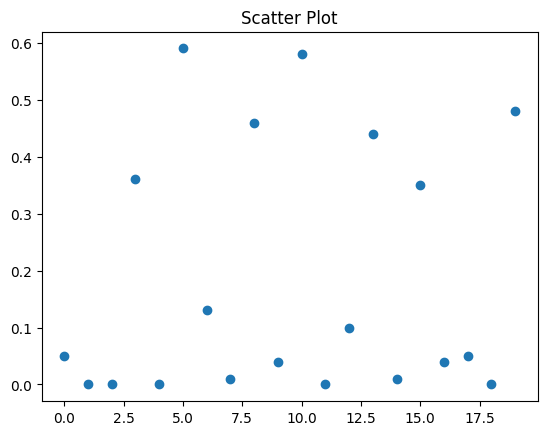

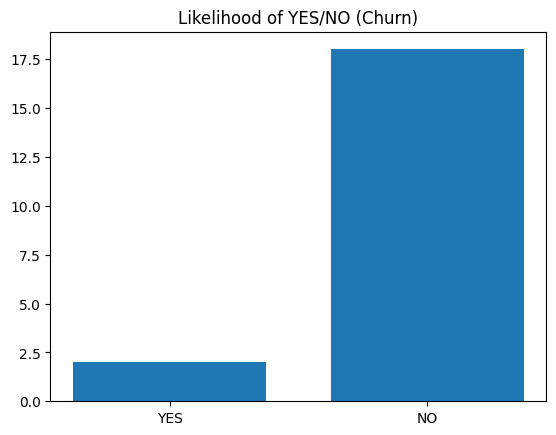

YES:  2
NO:  18

--- Service Evaluation ---


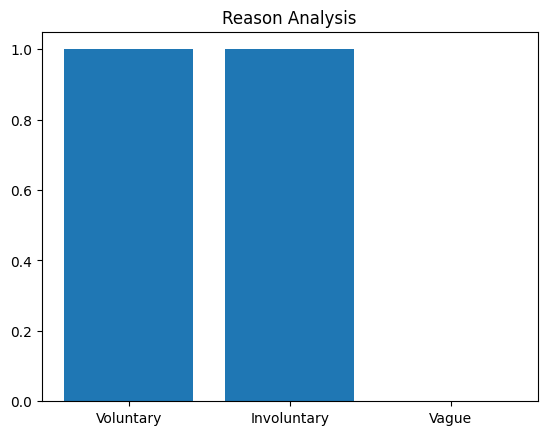

Voluntary:  1
Involuntary:  1
Vague:  0

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
0,696,59,2,4,101.566109,5992.400422,0,3468,0,0.03



--> Yearly Gross:  5992.400421942287 



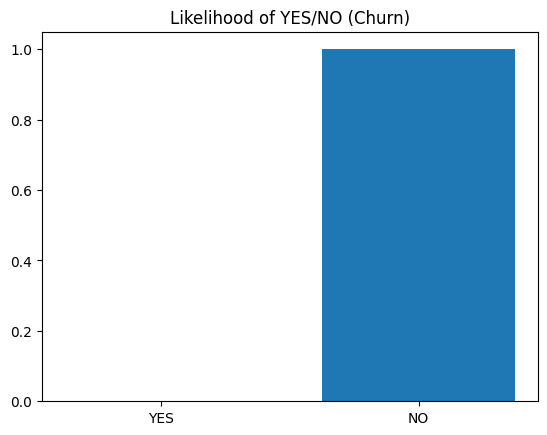

YES:  0
NO:  1

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
27,2622,1,1,4,75.910983,75.910983,1,2116,3,0.78
51,1596,4,1,3,25.862571,103.450282,0,3754,0,0.33
6,214,6,1,4,111.068305,666.409829,1,2390,1,0.69
35,894,8,1,2,48.426006,387.408052,1,2151,3,0.52
29,6971,10,1,1,37.511595,375.115952,0,2609,0,0.17
26,4073,10,1,1,84.507018,845.070180,1,2939,3,0.71
1,5564,10,1,1,90.850382,908.503819,1,2970,1,0.60
39,3019,13,3,3,105.261014,1368.393180,0,2722,0,0.33
9,6388,15,3,4,43.055709,645.835633,0,3624,0,0.11
20,908,15,3,2,110.656797,1659.851949,0,2909,0,0.43



--> Yearly Gross:  155979.67499103607 



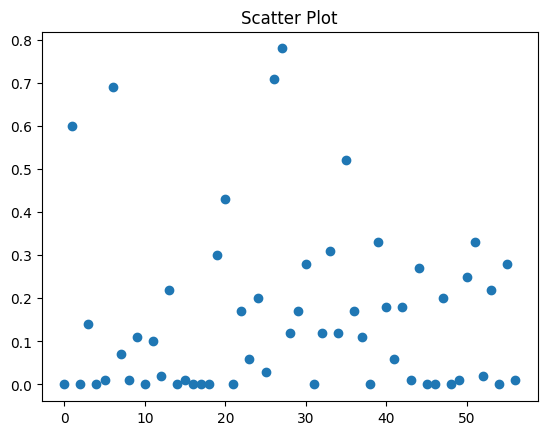

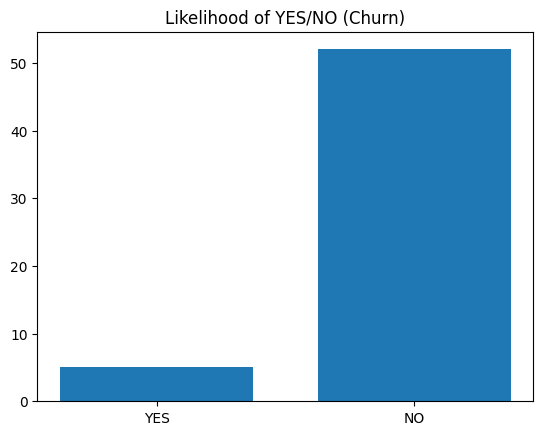

YES:  5
NO:  52

--- Service Evaluation ---


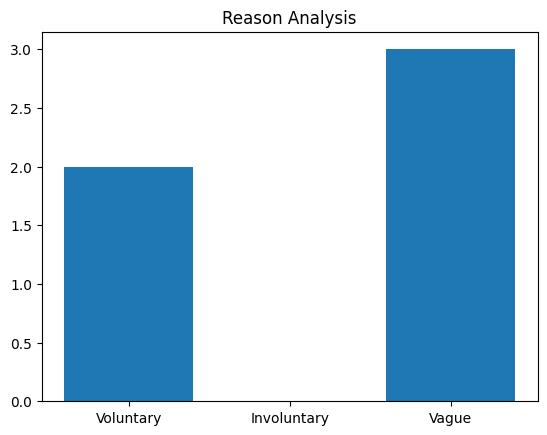

Voluntary:  2
Involuntary:  0
Vague:  3

--- New Sample ---


,Customer ID,Tenure Months,Contract Type,Payment Method,Monthly Fee,Total Charges,Churn Label,CLTV,Property,Score
12,1650,0,1,1,70.442274,0.000000,1,2375,3,0.65
18,4629,2,1,1,74.742039,149.484078,0,2686,0,0.45
91,3687,4,1,1,68.942064,275.768255,0,2538,0,0.28
29,4915,5,1,2,62.344131,311.720655,0,2648,0,0.08
99,7551,5,1,2,86.601069,433.005345,1,2823,3,0.62
...,...,...,...,...,...,...,...,...,...,...
74,2645,70,2,3,79.340915,5553.864019,0,3484,0,0.01
7,4568,70,2,1,84.355820,5904.907370,0,3082,0,0.01
33,325,70,2,4,116.954312,8186.801835,0,3394,0,0.11
60,1724,71,2,4,67.366098,4782.992967,0,2610,0,0.10



--> Yearly Gross:  253343.08647389588 



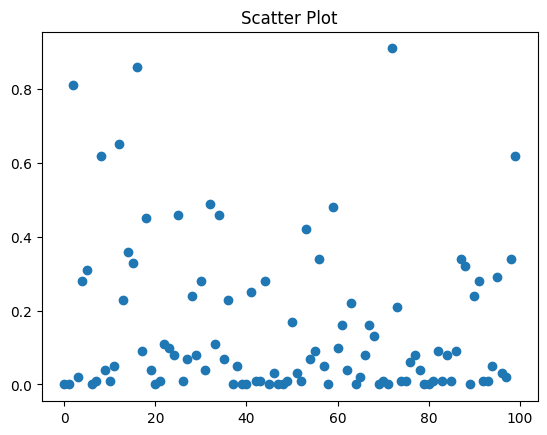

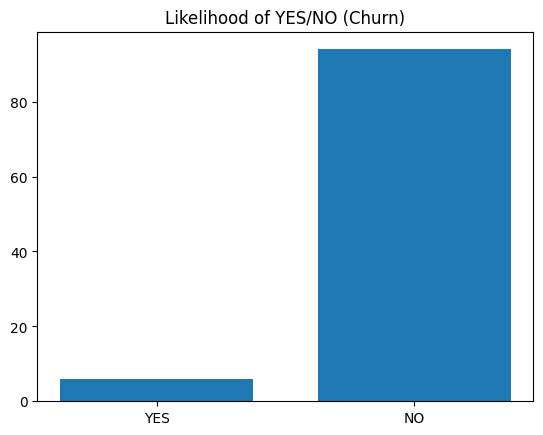

YES:  6
NO:  94

--- Service Evaluation ---


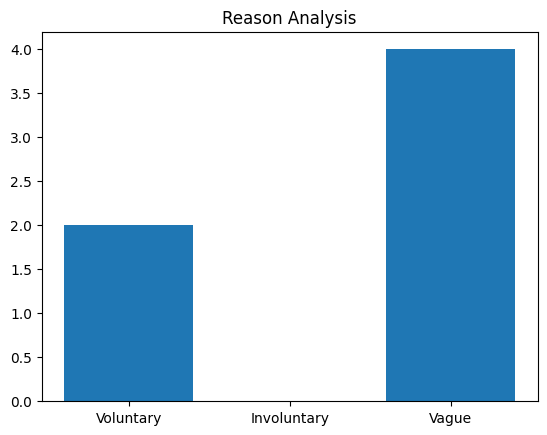

Voluntary:  2
Involuntary:  0
Vague:  4

--- Conclusion ---


,Rate
0,9.523810
1,0.000000
2,13.333333
3,18.750000
4,10.000000
5,0.000000
6,8.771930
7,6.000000


Churn Rate:  8.297384085213032
Standard Deviation:  5.9394582792776704


In [ ]:
# Rebuild Comprehensive Model
import sys
import matplotlib
import matplotlib.pyplot as plt

import random

import numpy as np
from numpy import extract

import pandas as pd

from google.colab import drive
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

drive.mount('/content/drive',force_remount=True)
Customers=pd.read_excel('/content/drive/MyDrive/AISC_Project/Telco_customer_churn.xlsx')

class Notebook:
  # Reason Categorization
  Voluntary=[
      "Competitor made better offer",
      "Competitor had better devices",
      "Competitor offered higher download speeds",
      "Competitor offered more data",
      "Product dissatisfaction",
      "Service dissatisfaction",
      "Long distance charges",
      "Attitude of service provider",
      "Attitude of support person",
      "Poor expertise of online support",
      "Poor expertise of phone support",
      "Extra data charges",
      "Price too high",
      "Lack of affordable download/upload speed",
      "Lack of self-service on Website"
  ]

  Involuntary=[
      "Limited range of services",
      "Network reliability",
      "Deceased",
      "Moved"
  ]

  Vague=[
      "Don't know"
  ]

  Hash_Contract={
      "Month-to-month":1,
      "Two year":2,
      "One year":3
  }

  Hash_Method={
      "Mailed check":1,
      "Electronic check":2,
      "Bank transfer (automatic)":3,
      "Credit card (automatic)":4
  }

  def __init__(self):
    self.Note=None
    self.Prediction=[]
    self.n=0
    # Data Planes
    self.Customer_ID=[]
    self.Tenure_Months=[]
    self.Contract_Type=[]
    self.Payment_Method=[]
    self.Monthly_Fee=[]
    self.Total_Charges=[]
    self.Churn_Label=[]
    self.CLTV=[]
    self.Property=[]

  def getProperty(self,x):
    if x in self.Voluntary:
      return 1
    if x in self.Involuntary:
      return 2
    if x in self.Vague:
      return 3
    else:
      return 0

  def getContract(self,x):
    if x>24:
      return 2
    if x>12:
      return 3
    else:
      return 1

  def GetDefault(self):
    self.Customer_ID=Customers["CustomerID"]
    self.Tenure_Months=Customers["Tenure Months"]
    self.Contract_Type=Customers["Contract"]
    self.Payment_Method=Customers["Payment Method"]
    self.Monthly_Fee=Customers["Monthly Charges"]
    self.Total_Charges=Customers["Total Charges"]
    self.Churn_Label=Customers["Churn Value"]
    self.CLTV=Customers["CLTV"]
    self.Property=[self.getProperty(items) for items in Customers["Churn Reason"]]

    self.n=len(self.Customer_ID)

  def GetData(self):
    # self.n=int(input("Number of customers: "))
    # for i in range(n):
    #   self.Customer_ID.append(str(input("Customer ID: ")))
    #   self.Tenure_Months.append(int(input("Tenure Months: ")))
    #   self.Contract_Type.append(str(input("Contract Type: ")))
    #   self.Payment_Method.append(str(input("Payment Method: ")))
    #   self.Monthly_Fee.append(float(input("Monthly Fee: ")))
    #   self.Total_Charges.append(self.Monthly_Fee[i]*self.Tenure_Months[i])
    #   self.Churn_Label.append(None)
    #   self.CLTV.append(float(input("CLTV: ")))


    self.n=random.randint(1,100)
    for i in range(self.n):
      self.Customer_ID.append(random.randint(1,8000))
      self.Tenure_Months.append(random.randint(0,72))
      self.Contract_Type.append(self.getContract(self.Tenure_Months[i]))
      self.Payment_Method.append(random.randint(1,4))
      self.Monthly_Fee.append(random.uniform(18.0,119.0))
      self.Total_Charges.append(self.Monthly_Fee[i]*self.Tenure_Months[i])
      self.Churn_Label.append(None)
      self.CLTV.append(random.randint(2000,4000))
      self.Property.append(None)

  def MakeNote(self):
    self.Note=pd.DataFrame({
        "Customer ID":self.Customer_ID,
        "Tenure Months":self.Tenure_Months,
        "Contract Type":self.Contract_Type,
        "Payment Method":self.Payment_Method,
        "Monthly Fee":self.Monthly_Fee,
        "Total Charges":self.Total_Charges,
        "Churn Label":self.Churn_Label,
        "CLTV":self.CLTV,
        "Property":self.Property
    })

  def PrintNote(self):
    return self.Note

  def Clean(self):
    self.Note=self.Note.drop(self.Note.loc[self.Note["Total Charges"]==" "].index)
    self.n=len(self.Note)

    # Hash for Machine Learning
    self.Note["Customer ID"]=list(range(len(self.Note)))
    self.Note["Contract Type"]=[self.Hash_Contract[items] for items in self.Note["Contract Type"]]
    self.Note["Payment Method"]=[self.Hash_Method[items] for items in self.Note["Payment Method"]]

  def Machine(self):
    FilteredData=self.Note.sample(frac=1).reset_index(drop=True)

    y=FilteredData["Churn Label"]

    ChosenFeatures=["Tenure Months","Monthly Fee","Total Charges","CLTV","Contract Type","Payment Method"]
    X=FilteredData[ChosenFeatures]

    train_X, val_X, train_y, val_y = train_test_split(X, y, test_size=0.01,random_state=42)

    _model=RandomForestRegressor(random_state=42)
    _model.fit(train_X,train_y)


    self.Prediction = _model.predict(val_X)

    plt.title("Prediction on random customers (@% from the sample)")

    x = np.array(list(range(len(self.Prediction))))
    y = np.array(self.Prediction)

    plt.bar(x,y,width=1)
    plt.show()

    plt.title("Likelihood of YES/NO (Churn)")

    GetLikelyYes=extract(self.Prediction>=0.5,self.Prediction)
    GetLikelyNo=extract(self.Prediction<0.5,self.Prediction)

    x=np.array(["YES","NO"])
    y=np.array([len(GetLikelyYes),len(GetLikelyNo)])

    plt.bar(x,y,width=0.75)
    plt.show()

    print(len(GetLikelyYes))
    print(len(GetLikelyNo))

  def MachineWithTester(self,Tester):
    print("\n--- New Sample ---")
    FilteredData=self.Note.sample(frac=1).reset_index(drop=True)

    y=FilteredData["Churn Label"]

    ChosenFeatures=["Tenure Months","Monthly Fee","Total Charges","CLTV","Contract Type","Payment Method"]
    X=FilteredData[ChosenFeatures]
    train_X, val_X, train_y, val_y = train_test_split(X, y, test_size=0.001,random_state=42)

    _model=RandomForestRegressor(random_state=42)
    _model.fit(train_X,train_y)


    self.Prediction = pd.DataFrame({"Score":_model.predict(Tester[ChosenFeatures])})

    result=pd.concat([Tester,self.Prediction],axis=1)
    result["Churn Label"]=np.where(result["Score"]>=0.5,1,0)

    def getPropertyByLabel(x):
      if x==0:
        return 0
      if x==1:
        return random.randint(1,3)

    result["Property"]=[getPropertyByLabel(items) for items in result["Churn Label"]]

    result=result.sort_values(by=["Tenure Months","Total Charges"])
    display(result)

    # def countLoss()

    print("\n--> Yearly Gross: ",result["Total Charges"].sum(),"\n")

    if len(self.Prediction)>1:
        plt.title("Scatter Plot")

        x=np.array(list(range(len(self.Prediction))))
        y=np.array(self.Prediction)

        plt.scatter(x,y)
        plt.show()

    plt.title("Likelihood of YES/NO (Churn)")

    GetLikelyYes=extract(self.Prediction>=0.5,self.Prediction)
    GetLikelyNo=extract(self.Prediction<0.5,self.Prediction)

    x=np.array(["YES","NO"])
    y=np.array([len(GetLikelyYes),len(GetLikelyNo)])

    plt.bar(x,y,width=0.75)
    plt.show()

    print("YES: ",len(GetLikelyYes))
    print("NO: ",len(GetLikelyNo))
    ChurnRateOnTesters.append(len(GetLikelyYes)*100.0/len(self.Prediction))

    if(len(GetLikelyYes)>0):
      print("\n--- Service Evaluation ---")
      plt.title("Reason Analysis")
      x = np.array(["Voluntary","Involuntary","Vague"])
      y = np.array([
          len(result.loc[result["Property"]==1]),
          len(result.loc[result["Property"]==2]),
          len(result.loc[result["Property"]==3])
      ])

      plt.bar(x,y)
      plt.show()

      print("Voluntary: ",len(result.loc[result["Property"]==1]))
      print("Involuntary: ",len(result.loc[result["Property"]==2]))
      print("Vague: ",len(result.loc[result["Property"]==3]))

def Casual():
  Book=Notebook()
  Book.GetDefault()
  Book.MakeNote()
  Book.Clean()
  Book.RateService()
  # Book.PrintNote()
  Book.Machine()

print("\n--- RANDOM TEST ---\n")

def SuperRandomMachine():
  loop=int(input("Refreshing Times: "))
  for i in range(loop):
    Book=Notebook()
    Book.GetDefault()
    Book.MakeNote()
    Book.Clean()

    NewBook=Notebook()
    NewBook.GetData()
    NewBook.MakeNote()

    Book.MachineWithTester(NewBook.Note)

    del Book
    del NewBook

ChurnRateOnTesters=[]
SuperRandomMachine()

Statistics=pd.DataFrame({"Rate":ChurnRateOnTesters})

print("\n--- Conclusion ---")

display(Statistics)
print("Churn Rate: ",Statistics["Rate"].mean())
print("Standard Deviation: ",np.std(Statistics["Rate"]))

# *A strong dataset : (Voluntary+Vague?>Involuntary)&(ChurnLabel:Yes<<No)



In [ ]:
Hash_Contract={
    "Month-to-month":1,
    "Two year":2,
    "One year":3
}

Hash_Method={
    "Mailed check":1,
    "Electronic check":2,
    "Bank transfer (automatic)":3,
    "Credit card (automatic)":4
}

Get_Contract={
    1:"Month-to-month",
    2:"Two year",
    3:"One year"
}

Get_Method={
    1:"Mailed check",
    2:"Electronic check",
    3:"Bank transfer (automatic)",
    4:"Credit card (automatic)"
}


Customers["Payment Method"].unique()

array(['Mailed check', 'Electronic check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

In [ ]:
Customers['Contract'].unique()

array(['Month-to-month', 'Two year', 'One year'], dtype=object)